# C1 · Notebook 01 — EDA of the raw dataset (1950–2024)
**Business Intelligence · IIB423T-1 · UDD** — **Group 06** — Maximiliano Sandoval and Benjamín Toloza

**Line of inquiry (selected after W1):** *How much does the starting position determine the race result, and does it vary by circuit?*
Proposed user: a team strategist deciding how far to lean the (single, because of parc fermé) car setup towards qualifying or towards race pace.

**Purpose of this notebook (EDA 1).** Explore the dataset **as downloaded** from Kaggle
([rohanrao, *Formula 1 World Championship (1950–2024)*](https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020), data from Ergast),
before any filtering: what each table contains, its coverage over time, missing values, integrity between tables,
first distributions and correlations. The goal is to **justify with evidence** the period and the tables used later.

| Notebook | Role |
|---|---|
| **01 (this one)** | EDA of the raw dataset → decisions on period, tables and quality issues |
| 02 | Cleaning → one analytic table (one row = one driver in one race, 2014–2024) |
| 03 | EDA driven by the selected KPI (IDC) and its supporting KPIs |

**How to run:** open the whole `GROUP_06_C1` folder in VS Code or Jupyter and *Restart & Run All*. The notebook only reads `data/raw/`.

## 0. Setup
Libraries, project-relative paths and plot style. Missing values are written as `\N` in every CSV, so `na_values="\\N"`
turns them into `NaN` and numeric columns are read as numbers instead of text.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from pathlib import Path

def find_root():
    """Finds the project folder (the one containing data/raw/races.csv), starting from where the
    notebook runs and moving up one folder at a time. Works the same in Jupyter and in VS Code."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "data" / "raw" / "races.csv").exists():
            return base
    raise FileNotFoundError("data/raw/races.csv not found. Open the whole GROUP_06_C1 folder "
                            "(File > Open Folder) and check that the Kaggle CSVs are in data/raw/.")

ROOT = find_root()
RAW, PROC, FIG = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "analysis" / "figures"
for d in (PROC, FIG):
    os.makedirs(d, exist_ok=True)

NA = "\\N"                                   # how missing values are written in this dataset
read = lambda file: pd.read_csv(RAW / file, na_values=NA)

# Plot style: one colour per series, thin marks, light grid, text in grey (never in the series colour)
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e6e3"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])   # red (-) · grey (0) · blue (+)
plt.rcParams.update({
    "figure.figsize": (8, 4.2), "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#bdbcb7",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "font.size": 9.5,
    "legend.frameon": False})

def save_fig(fig, name):
    """Saves the figure in analysis/figures/ (used by the report) and shows it in the notebook."""
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def summary(s):
    """Classical and robust summary of a numeric variable (mean/SD vs median/IQR, shape)."""
    s = pd.Series(s).dropna()
    return pd.Series({"n": len(s), "mean": s.mean(), "std": s.std(), "min": s.min(), "p25": s.quantile(.25),
                      "median": s.median(), "p75": s.quantile(.75), "max": s.max(),
                      "IQR": s.quantile(.75) - s.quantile(.25), "skew": s.skew(), "kurtosis": s.kurt()})

print("Project folder:", ROOT.name, "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scipy", __import__("scipy").__version__, "| matplotlib", matplotlib.__version__)

Project folder: GROUP_06_C1 | pandas 3.0.2 | numpy 2.4.4 | scipy 1.17.1 | matplotlib 3.10.9


## 1. Inventory: what does each table represent?
Before any statistic we need the **unit of observation** of each table (what one row is) and its **key** (the columns that
identify a row). If the key is not unique, counts and averages would be wrong. We also record size, period covered and the
share of empty cells.

*Note:* the Kaggle package has 14 CSVs. `seasons.csv` (only a Wikipedia URL per year) and `constructor_results.csv`
(points per team per race, already contained in `results.csv`) add nothing to this question and were not downloaded into `data/raw/`.

In [2]:
TABLES = {  # file: (unit of observation, proposed key)
    "races.csv":                 ("one Grand Prix",                      ["raceId"]),
    "results.csv":               ("one driver in one race",              ["raceId", "driverId"]),
    "qualifying.csv":            ("one driver's qualifying in one race", ["raceId", "driverId"]),
    "lap_times.csv":             ("one lap of one driver in one race",   ["raceId", "driverId", "lap"]),
    "pit_stops.csv":             ("one pit stop of one driver",          ["raceId", "driverId", "stop"]),
    "sprint_results.csv":        ("one driver in one sprint race",       ["raceId", "driverId"]),
    "driver_standings.csv":      ("driver championship after a race",    ["raceId", "driverId"]),
    "constructor_standings.csv": ("team championship after a race",      ["raceId", "constructorId"]),
    "drivers.csv":               ("one driver (lookup)",                 ["driverId"]),
    "constructors.csv":          ("one team (lookup)",                   ["constructorId"]),
    "circuits.csv":              ("one circuit (lookup)",                ["circuitId"]),
    "status.csv":                ("one finishing status (lookup)",       ["statusId"]),
}
raw = {f.replace(".csv", ""): read(f) for f in TABLES}
races = raw["races"]
year_of = races.set_index("raceId")["year"]

rows = []
for f, (unit, key) in TABLES.items():
    df = raw[f.replace(".csv", "")]
    yrs = df["raceId"].map(year_of) if "raceId" in df else (df["year"] if "year" in df else None)
    rows.append({"table": f, "unit of observation": unit, "key": " + ".join(key),
                 "rows": len(df), "columns": df.shape[1],
                 "duplicated keys": int(df.duplicated(key).sum()),
                 "years": f"{int(yrs.min())}–{int(yrs.max())}" if yrs is not None else "(no date)",
                 "% empty cells": round(100 * df.isna().mean().mean(), 1)})
inventory = pd.DataFrame(rows)
inventory

,table,unit of observation,key,rows,columns,duplicated keys,years,% empty cells
0,races.csv,one Grand Prix,raceId,1125,18,0,1950–2024,56.0
1,results.csv,one driver in one race,raceId + driverId,26759,18,91,1950–2024,25.5
2,qualifying.csv,one driver's qualifying in one race,raceId + driverId,10494,9,0,1994–2024,12.4
3,lap_times.csv,one lap of one driver in one race,raceId + driverId + lap,589081,6,0,1996–2024,0.0
4,pit_stops.csv,one pit stop of one driver,raceId + driverId + stop,11371,7,0,2011–2024,0.0
5,sprint_results.csv,one driver in one sprint race,raceId + driverId,360,16,0,2021–2024,1.3
6,driver_standings.csv,driver championship after a race,raceId + driverId,34863,7,0,1950–2024,0.0
7,constructor_standings.csv,team championship after a race,raceId + constructorId,13391,7,0,1958–2024,0.0
8,drivers.csv,one driver (lookup),driverId,861,9,0,(no date),20.1
9,constructors.csv,one team (lookup),constructorId,212,5,0,(no date),0.0


**Reading.** The dataset is relational: fact tables (`results`, `qualifying`, `lap_times`, `pit_stops`, standings) are linked
through `raceId`, `driverId`, `constructorId`, `circuitId` and `statusId` to the lookup tables. Every proposed key is unique
**except `results`**: 91 rows repeat the pair (race, driver). That is examined in section 5. The tables do **not** cover the
same years (`qualifying` starts in 1994, `lap_times` in 1996, `pit_stops` in 2011, sprints in 2021): section 3 looks at this in detail.

## 2. Integrity between tables (referential checks)
A join is only safe if every identifier in a fact table exists in the lookup table it points to (no *orphans*).
We test every relationship instead of assuming it.

In [3]:
FK = [("results", "raceId", "races"), ("results", "driverId", "drivers"), ("results", "constructorId", "constructors"),
      ("results", "statusId", "status"), ("races", "circuitId", "circuits"), ("qualifying", "raceId", "races"),
      ("qualifying", "driverId", "drivers"), ("lap_times", "raceId", "races"), ("lap_times", "driverId", "drivers"),
      ("pit_stops", "raceId", "races"), ("sprint_results", "raceId", "races"),
      ("constructor_standings", "raceId", "races"), ("constructor_standings", "constructorId", "constructors"),
      ("driver_standings", "driverId", "drivers")]
fk = pd.DataFrame([{"relationship": f"{t}.{c} → {ref}", "rows checked": len(raw[t]),
                    "orphans": int((~raw[t][c].isin(raw[ref][c])).sum())} for t, c, ref in FK])
display(fk)

# Are there lap_times / pit_stops for a (race, driver) that has no result? And results with no qualifying (1994+)?
res_pairs = raw["results"].set_index(["raceId", "driverId"]).index
for t in ["lap_times", "pit_stops", "qualifying"]:
    pairs = raw[t].drop_duplicates(["raceId", "driverId"]).set_index(["raceId", "driverId"]).index
    print(f"{t:<11} (race, driver) pairs without a row in results: {(~pairs.isin(res_pairs)).sum()}")

,relationship,rows checked,orphans
0,results.raceId → races,26759,0
1,results.driverId → drivers,26759,0
2,results.constructorId → constructors,26759,0
3,results.statusId → status,26759,0
4,races.circuitId → circuits,1125,0
5,qualifying.raceId → races,10494,0
6,qualifying.driverId → drivers,10494,0
7,lap_times.raceId → races,589081,0
8,lap_times.driverId → drivers,589081,0
9,pit_stops.raceId → races,11371,0


lap_times   (race, driver) pairs without a row in results: 0
pit_stops   (race, driver) pairs without a row in results: 0
qualifying  (race, driver) pairs without a row in results: 0


**Reading.** No orphans: every identifier points to an existing record, so the joins used later are structurally safe.
This is a necessary condition, not a sufficient one: a join can still **duplicate rows** if the relationship is not the one
we expect (one-to-one vs. many-to-one). That is tested with `validate=` when each join is used (notebook 02).

## 3. Temporal coverage: which years can answer the question?
The question needs, for the same races: starting position (`results.grid`), qualifying (`qualifying`), laps (`lap_times`) and the
team's strength (`constructor_standings`). We compute, for each table and season, **the share of that season's races that have data**.

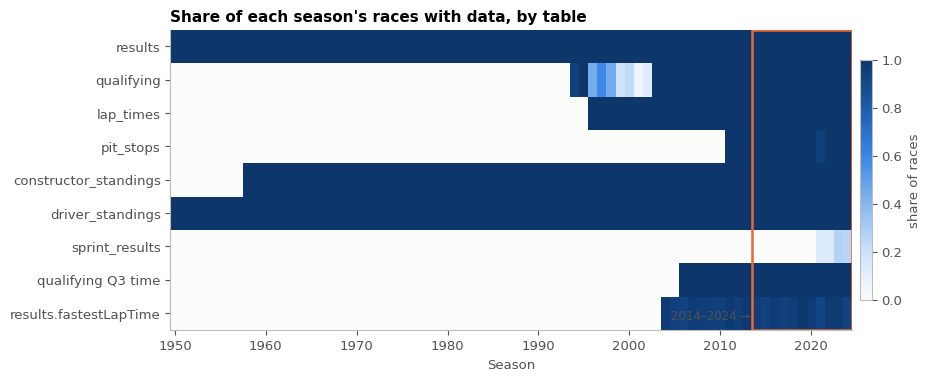

,results,qualifying,lap_times,pit_stops,constructor_standings,driver_standings,sprint_results,qualifying Q3 time,results.fastestLapTime
year,,,,,,,,,
1994,1.0,0.94,0.0,0.00,1.0,1.0,0.00,0.0,0.00
2003,1.0,1.00,1.0,0.00,1.0,1.0,0.00,0.0,0.00
2006,1.0,1.00,1.0,0.00,1.0,1.0,0.00,1.0,0.93
2011,1.0,1.00,1.0,1.00,1.0,1.0,0.00,1.0,0.98
2014,1.0,1.00,1.0,1.00,1.0,1.0,0.00,1.0,0.96
2021,1.0,1.00,1.0,0.95,1.0,1.0,0.14,1.0,0.92
2024,1.0,1.00,1.0,1.00,1.0,1.0,0.25,1.0,0.93


In [4]:
n_races = races.groupby("year").size()
cov = {}
for t in ["results", "qualifying", "lap_times", "pit_stops", "constructor_standings", "driver_standings", "sprint_results"]:
    cov[t] = raw[t].assign(year=raw[t]["raceId"].map(year_of)).groupby("year")["raceId"].nunique() / n_races
cov = pd.DataFrame(cov).reindex(n_races.index).fillna(0)

# q1/q2/q3 availability: the knockout format with three sessions exists from 2006
q = raw["qualifying"].assign(year=raw["qualifying"]["raceId"].map(year_of))
cov["qualifying Q3 time"] = q.groupby("year")["q3"].apply(lambda s: s.notna().any()).reindex(n_races.index).fillna(False).astype(float)
# fastest-lap fields in results appear from 2004
r = raw["results"].assign(year=raw["results"]["raceId"].map(year_of))
cov["results.fastestLapTime"] = r.groupby("year")["fastestLapTime"].apply(lambda s: s.notna().mean()).reindex(n_races.index)

fig, ax = plt.subplots(figsize=(10, 3.9))
im = ax.imshow(cov.T.values, aspect="auto", cmap=SEQ, vmin=0, vmax=1, interpolation="nearest",
               extent=(n_races.index.min() - .5, n_races.index.max() + .5, len(cov.columns) - .5, -.5))
ax.set_yticks(range(len(cov.columns)), cov.columns)
ax.axvspan(2013.5, 2024.5, fill=False, edgecolor=ORANGE, linewidth=1.8)
ax.text(2013.3, len(cov.columns) - 0.8, "2014–2024 →", color=INK2, ha="right", fontsize=8.5)
ax.grid(False)
ax.set(title="Share of each season's races with data, by table", xlabel="Season")
fig.colorbar(im, ax=ax, shrink=0.8, pad=0.01, label="share of races")
save_fig(fig, "E1_01_coverage_by_table_year")
display(cov.loc[[1994, 2003, 2006, 2011, 2014, 2021, 2024]].round(2))

**Reading.** `results`, both standings tables and the lookup tables cover the whole history, but the tables that describe **how**
the result was built appear late: qualifying is complete only from **2003**, the three-session knockout (Q3 time) from **2006**,
lap-by-lap data from **1996** and pit stops from **2011** (Belgium 2021 has none: it was not really raced). Sprints exist
only from 2021 and only on some weekends. Any analysis that relates qualifying pace, first-lap position and team strength
to the result is therefore only complete from 2011 onwards.

## 4. How much did the championship itself change? (comparability across eras)
Coverage is not the only criterion: the numbers must also **mean the same** across years. We check three things that affect
our variables: calendar size and grid size, the points system and car reliability (retirements).

,races,drivers per race (median),points to the winner,% finished
year,,,,
1950,7,21.0,9.0,50.0
1970,13,23.0,9.0,42.2
1990,16,35.0,9.0,37.6
2003,16,20.0,10.0,65.3
2010,19,24.0,25.0,74.1
2014,19,22.0,25.0,78.9
2019,21,20.0,25.0,85.7
2022,22,20.0,25.0,83.2
2024,24,20.0,25.0,88.7


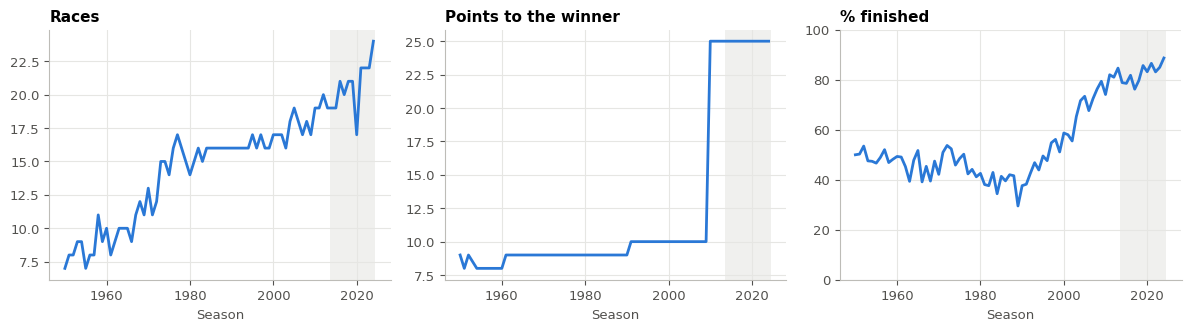

In [5]:
status = raw["status"]
r = r.merge(status, on="statusId", how="left")
r["finished"] = r["status"].eq("Finished") | r["status"].str.match(r"^\+\d+ Laps?$")

per_year = pd.DataFrame({
    "races": n_races,
    "drivers per race (median)": r.groupby(["year", "raceId"]).size().groupby("year").median(),
    "points to the winner": r[r["positionOrder"] == 1].groupby("year")["points"].median(),
    "% finished": 100 * r.groupby("year")["finished"].mean(),
})
display(per_year.loc[[1950, 1970, 1990, 2003, 2010, 2014, 2019, 2022, 2024]].round(1))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, col, color in zip(axes, ["races", "points to the winner", "% finished"], [BLUE, BLUE, BLUE]):
    ax.plot(per_year.index, per_year[col], color=color, linewidth=2)
    ax.axvspan(2013.5, 2024.5, color=GRID, alpha=.6, linewidth=0)
    ax.set(title=col.capitalize(), xlabel="Season")
axes[2].set_ylim(0, 100)
save_fig(fig, "E1_02_championship_changes")

**Reading.**
- **Calendar:** from 7 races (1950s) to 24 (2024). More races per season means more observations per circuit in recent years.
- **Points:** the winner got 8, 9 or 10 points for decades and **25 since 2010** (plus fastest-lap/sprint bonuses in some years).
  Points are not comparable across eras, which is why our KPIs use **positions**, not points.
- **Reliability:** until the 1990s fewer than half of the starters finished; since the 2010s about 80–85 % do. A
  retirement cuts the link between start and result, so mixing eras would mix reliability with the effect we want to measure.

Together with section 3, this supports the W1 decision to work with **2014–2024**: a single engine formula (V6 turbo-hybrid),
a single points scale (25 to the winner), knockout qualifying, and all the tables we need present.

## 5. Duplicates and special codes in `results`
Section 1 found 91 repeated (race, driver) pairs. We also examine the special values that would distort a statistic if read naively:
`grid = 0` and `position` empty.

In [6]:
dup = r[r.duplicated(["raceId", "driverId"], keep=False)]
print(f"Repeated (race, driver) keys: {r.duplicated(['raceId', 'driverId']).sum()} "
      f"({len(dup)} rows involved), seasons: {sorted(int(y) for y in dup['year'].unique())}")
display(dup.sort_values(["raceId", "driverId"])[["year", "raceId", "driverId", "constructorId", "grid", "positionOrder", "status"]].head(6))

special = pd.DataFrame({
    "grid = 0 (%)": 100 * r.groupby(r["year"] // 10 * 10)["grid"].apply(lambda s: (s == 0).mean()),
    "position empty (%)": 100 * r.groupby(r["year"] // 10 * 10)["position"].apply(lambda s: s.isna().mean()),
    "'Did not qualify' rows": r.groupby(r["year"] // 10 * 10)["status"].apply(lambda s: s.str.contains("qualify").sum()),
}).rename_axis("decade")
display(special.round(1))

Repeated (race, driver) keys: 91 (176 rows involved), seasons: [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1960, 1961, 1962, 1964, 1978]


,year,raceId,driverId,constructorId,grid,positionOrder,status
13188,1978,540,229,54,0,26,Did not qualify
13191,1978,540,229,57,0,29,Did not prequalify
17362,1964,717,373,172,1,7,Out of fuel
24298,1964,717,373,172,1,12,Injection
17740,1962,733,465,172,0,22,Withdrew
17743,1962,733,465,97,0,25,Withdrew


,grid = 0 (%),position empty (%),'Did not qualify' rows
decade,,,
1950,3.4,50.2,50
1960,9.4,50.1,75
1970,9.2,50.8,331
1980,12.7,58.5,545
1990,8.4,51.2,349
2000,0.2,30.2,2
2010,0.7,17.9,4
2020,2.7,12.7,0


**Reading.**
- The 91 repeated keys (176 rows) are all from **1950–1978**: in that era a driver could **share a car** with a team-mate or
  be entered in **two cars** in the same Grand Prix (e.g. one that did not qualify and one that did). They are real, not
  recording errors, and they are outside our period (0 duplicates in 2014–2024).
- `grid = 0` does not mean "pole position". In old seasons it marks drivers who **did not qualify** or did not start
  (thousands of "Did not qualify" rows before 1990); in the modern era it marks a **pit-lane start**. It must never be treated
  as a number smaller than 1.
- `position` is empty when a driver is **not classified**; `positionOrder` always has a value (retirements at the bottom).
  Choosing one or the other is a measurement decision (notebook 02).

## 6. First distributions (whole history)
Histograms of the main variables of the question, for all 26,759 results. The goal is not yet to answer the question but to
see the **shape** of the variables (range, asymmetry, special values).

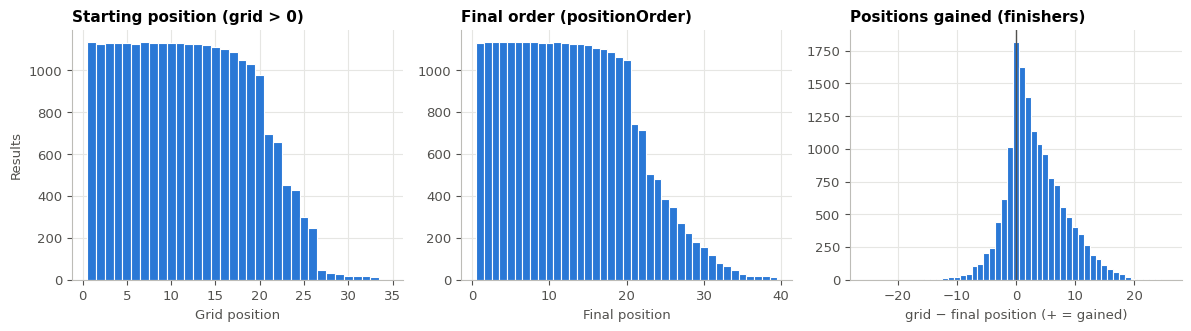

,grid (>0),positionOrder,positions gained (finishers)
n,25121.00,26759.00,15105.00
mean,11.86,12.79,3.20
std,6.83,7.67,4.92
min,1.00,1.00,-18.00
p25,6.00,6.00,0.00
median,12.00,12.00,2.00
p75,17.00,18.00,6.00
max,34.00,39.00,30.00
IQR,11.00,12.00,6.00
skew,0.21,0.40,0.52


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].hist(r.loc[r["grid"] > 0, "grid"], bins=np.arange(0.5, 35.5, 1), color=BLUE, edgecolor="white", linewidth=.8)
axes[0].set(title="Starting position (grid > 0)", xlabel="Grid position", ylabel="Results")
axes[1].hist(r["positionOrder"], bins=np.arange(0.5, 40.5, 1), color=BLUE, edgecolor="white", linewidth=.8)
axes[1].set(title="Final order (positionOrder)", xlabel="Final position")
gain = (r["grid"] - r["positionOrder"])[(r["grid"] > 0) & r["finished"]]
axes[2].hist(gain, bins=np.arange(-25.5, 26.5, 1), color=BLUE, edgecolor="white", linewidth=.8)
axes[2].axvline(0, color=INK2, linewidth=1)
axes[2].set(title="Positions gained (finishers)", xlabel="grid − final position (+ = gained)")
save_fig(fig, "E1_03_histograms_all_years")
display(pd.DataFrame({"grid (>0)": summary(r.loc[r["grid"] > 0, "grid"]),
                      "positionOrder": summary(r["positionOrder"]),
                      "positions gained (finishers)": summary(gain)}).round(2))

**Reading.** Grid and final order are close to **uniform** over 1–20 and then thin out (older seasons had grids of 26–34 cars).
They are **ranks**, so their "distribution" mostly reflects the number of cars per race; this is why rank methods
(Spearman / Kendall) are the right tool. The distribution of *positions gained* among finishers is shifted
**above 0** (median +2, mean +3.2, right-skewed): finishers gain places mainly because cars ahead of them retire. That effect depends on reliability, again
pointing to an era-specific analysis.

## 7. Correlations: which variables move with the final position?
Spearman correlation matrix (rank-based, suitable for ordinal positions) of the numeric fields of `results`, for the
seasons where all of them exist (2004–2024: `rank` of the fastest lap and its speed start in 2004). Finishers only, so that
retirements do not dominate the pattern.

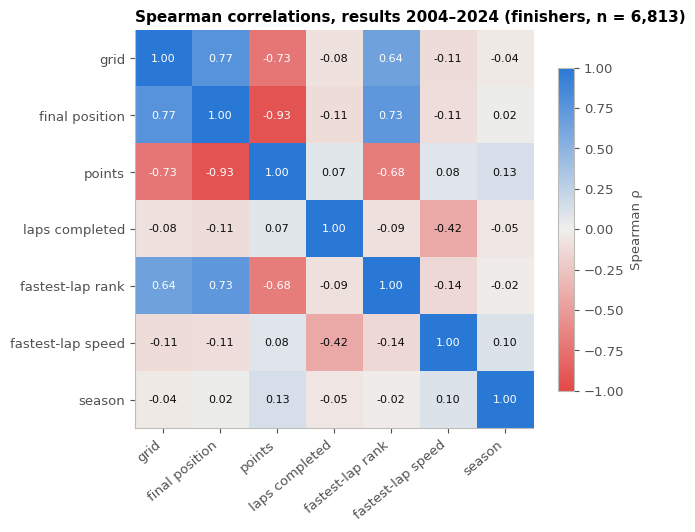

In [8]:
cols = {"grid": "grid", "positionOrder": "final position", "points": "points", "laps": "laps completed",
        "rank": "fastest-lap rank", "fastestLapSpeed": "fastest-lap speed", "year": "season"}
m = r[(r["year"] >= 2004) & r["finished"] & (r["grid"] > 0)][list(cols)].rename(columns=cols).dropna()
corr = m.corr(method="spearman")

fig, ax = plt.subplots(figsize=(6.6, 5.4))
im = ax.imshow(corr.values, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right"); ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iat[i, j]) > .6 else INK)
ax.grid(False); ax.set_title(f"Spearman correlations, results 2004–2024 (finishers, n = {len(m):,})")
fig.colorbar(im, ax=ax, shrink=.8, label="Spearman ρ")
save_fig(fig, "E1_04_spearman_matrix_results")

**Reading.** The final position is strongly associated with the **grid** (ρ = 0.77) and with the **fastest-lap rank**
(ρ = 0.73, a proxy of race pace), and, by construction, negatively with points (−0.93). Grid and fastest-lap rank are also
correlated with each other (0.64): fast cars qualify well **and** race well. This is the confounding the KPI analysis must
address (team strength), and it is why notebook 02 adds the team's championship position before each race.
Fastest-lap *speed* and *season* are almost unrelated to the result (|ρ| ≤ 0.13): speed depends on the circuit (its
−0.42 with laps completed reflects that long, fast circuits have fewer laps), not on who wins.

## 8. The question across the whole history: start → result by season
Before narrowing the period, we look at the relationship of interest across 75 seasons: for each race, Spearman between grid and
final position (finishers, grid > 0, at least 8 finishers), summarised by the season median.

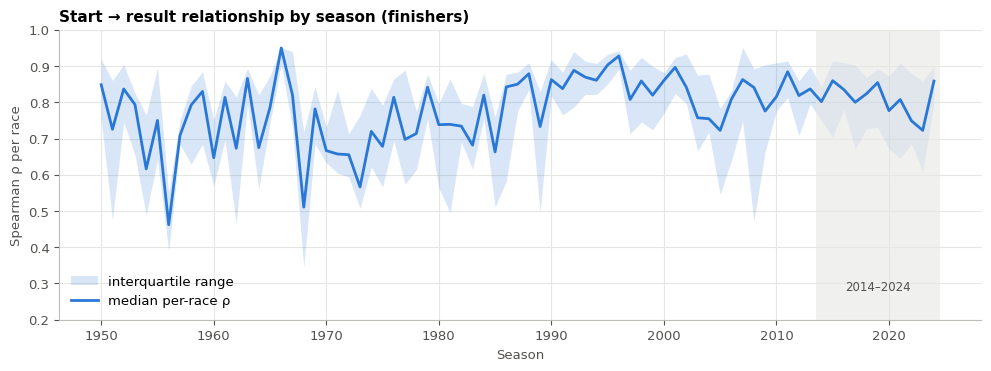

Races with a computable ρ: 1049 of 1125


,median,q25,q75,races
year,,,,
1950,0.848,0.754,0.919,6
1970,0.667,0.633,0.732,9
1990,0.863,0.818,0.918,15
2005,0.723,0.546,0.783,18
2014,0.802,0.750,0.842,19
2024,0.859,0.799,0.900,24


In [9]:
base = r[(r["grid"] > 0) & r["finished"]]
def race_rho(d):
    return stats.spearmanr(d["grid"], d["positionOrder"])[0] if len(d) >= 8 else np.nan
rho = base.groupby("raceId")[["grid", "positionOrder"]].apply(race_rho).rename("rho").to_frame()
rho["year"] = rho.index.map(year_of)
by_year = rho.groupby("year")["rho"].agg(median="median", q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75), races="count")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.fill_between(by_year.index, by_year["q25"], by_year["q75"], color=BLUE, alpha=.18, linewidth=0, label="interquartile range")
ax.plot(by_year.index, by_year["median"], color=BLUE, linewidth=2, label="median per-race ρ")
ax.axvspan(2013.5, 2024.5, color=GRID, alpha=.6, linewidth=0)
ax.text(2019, 0.28, "2014–2024", ha="center", color=INK2, fontsize=8.5)
ax.set(title="Start → result relationship by season (finishers)", xlabel="Season", ylabel="Spearman ρ per race", ylim=(0.2, 1))
ax.legend(loc="lower left")
save_fig(fig, "E1_05_rho_by_season_all_history")
print(f"Races with a computable ρ: {rho['rho'].notna().sum()} of {len(races)}")
display(by_year.loc[[1950, 1970, 1990, 2005, 2014, 2024]].round(3))

**Reading.** Among finishers the start → result relationship has been **strong in every era**. Before the late 1980s it
jumps from year to year (0.46–0.95) because seasons had few races and few finishers per race; since then it is stable at
**≈ 0.75–0.9** with a narrower spread between races. Inside 2014–2024 it dips in 2020–2023 and returns to 0.86 in 2024. That is consistent with the
literature cited in W1 (qualifying as the best single predictor of the result). It also shows that each era must be analysed
on its own: the level of the relationship depends on the regulations and on reliability. Within 2014–2024 the question is
whether it **varies by circuit** enough to guide a setup decision, and how much of it is really the car.

## 9. Five Cs of the raw dataset and decisions for the cleaning step
The C1 brief defines the five lenses as **Clean, Consistent, Conformed, Current and Comprehensive** (W1 used a different list).
Each lens is applied to the raw data below; notebook 02 (section 11) applies them again to the prepared table.

| C | What it asks | Finding in the raw data | Decision for notebook 02 |
|---|---|---|---|
| **Clean** | Validity and duplicates | `\N` encodes missing values; `grid = 0` is a code, not a position; 91 repeated (race, driver) keys, all 1950–1978 (shared cars) | Read `\N` as NaN; never use 0 as a position; the duplicates fall outside the period |
| **Consistent** | Stable definitions and rules over time | The meaning of `grid = 0` changed (did not qualify → pit-lane start); points to the winner 8–10 → 25 (2010); Q3 exists only from 2006; finishing rate < 50 % → 80–90 % | Restrict to 2014–2024; measure with positions, not points |
| **Conformed** | Shared entities and codes agree across tables | 0 orphan ids in 14 relationships; the same team appears under several names and ids (Force India → Racing Point → Aston Martin) | Validate every join (`validate=`, row counts); group teams by lineage |
| **Current** | Age and availability vs the decision | Data end with the 2024 season (Ergast stopped updating) | Enough for a historical decision; state the cut-off |
| **Comprehensive** | Coverage of population, fields, periods; what is unobserved | Qualifying complete from 2003, pit stops from 2011, Belgium 2021 has 1 lap; no weather, safety-car, tyre or car-setup fields at all | Work with 2014–2024; exclude Belgium 2021; declare the unobserved factors as limitations |

**Tables kept for the analytic table:** `races`, `results`, `qualifying`, `lap_times`, `pit_stops` (to remove in/out laps from race
pace), `constructor_standings`, `drivers`, `constructors`, `circuits`, `status`, `sprint_results`.
`driver_standings` is kept only as a possible control for C1 extensions.